In [36]:
import pandas as pd
properties_data = pd.read_csv('../data_to_use/preprocessed_data/cleaned_properties.csv')
# rename 'property_id' column to 'id' to match amenities_data
properties_data.rename(columns={'property_id': 'id'}, inplace=True)
properties_data.head()

,id,latitude,longitude,street_address,suburb,postcode,weekly_rent_number,property_type,bedrooms,bathrooms,...,services_available_pay_tv,services_available_solar_power,services_available_water,services_heating,spa_outside,spa_spa,sport_gym,sport_pool,sport_tennis_court,views_garden_views
0,515812,-37.869108,144.990422,"108/126 Chapel Street,",st kilda,3182,550.0,Apartment,1,1,...,0,0,0,0,0,0,0,0,0,0
1,802350,-37.802986,144.961405,"24 Barkly Place,",carlton,3053,360.0,Studio,1,1,...,0,0,0,0,0,0,0,0,0,0
2,802356,-37.808700,144.984130,"45 Victoria Parade,",collingwood,3066,360.0,Studio,1,1,...,0,0,0,0,0,0,0,0,0,0
3,802372,-37.714742,145.060900,"116-130 Main Drive,",macleod,3085,250.0,Studio,0,1,...,0,0,0,0,0,0,0,0,0,0
4,802379,-37.875928,145.046426,"117/60 Waverley Road,",malvern east,3145,540.0,Apartment,2,1,...,0,0,0,0,0,0,0,0,0,0


In [37]:
sa2_panel = pd.read_csv('../data_to_use/sa2_panel/sa2_panel.csv')
sa2_panel.head()

,sa2_code_2021,sa2_name,year,feature,value,status
0,201011481,Ballarat East - Warrenheip,2001,population,8018.0,observed
1,201011481,Ballarat East - Warrenheip,2002,population,8066.0,observed
2,201011481,Ballarat East - Warrenheip,2003,population,8080.0,observed
3,201011481,Ballarat East - Warrenheip,2004,population,8061.0,observed
4,201011481,Ballarat East - Warrenheip,2005,population,8057.0,observed


In [38]:
population_data = sa2_panel.loc[sa2_panel['feature'] == 'population']
population_data.drop(columns=['year'], inplace=True)
population_data.head(1)

,sa2_code_2021,sa2_name,feature,value,status
0,201011481,Ballarat East - Warrenheip,population,8018.0,observed


# Additional data
- Household dwelling data: `data/forecasting/Household_Dwelling_Forecast_2136_CleanedV2.csv`

In [58]:
dwellings_data = pd.read_csv('../data_to_use/forecasting/Household_Dwelling_Forecast_2136_CleanedV2.csv')
dwellings_data.head()

,Unnamed: 0,GCCSA,SA4_Code,SA3_Code,SA2_Code,Region_Type,SA2_Name,Dwellings_2021,Dwellings_2026,Dwellings_2031,Dwellings_2036
0,0,2RVIC,201,20101,201011001,SA2,Alfredton,6245.0,8252.000000,9732.000000,10830.000000
1,1,2RVIC,201,20101,201011002,SA2,Ballarat,5970.0,6134.548371,6350.037451,6553.095884
2,2,2RVIC,201,20101,201011005,SA2,Buninyong,2768.0,2943.325691,3199.637967,3445.433425
3,3,2RVIC,201,20101,201011006,SA2,Delacombe,4172.0,6585.376102,8740.266903,10770.851234
4,4,2RVIC,201,20101,201011007,SA2,Smythes Creek,1490.0,1600.000000,1720.000000,1856.363636


In [60]:
dwellings_data = pd.read_csv('../data_to_use/forecasting/Household_Dwelling_Forecast_2136_CleanedV2.csv')
cols_to_keep = ['SA2_Name', 'Dwellings_2021', 'Dwellings_2026']
dwellings_data = dwellings_data[cols_to_keep]
dwellings_data.head()

,SA2_Name,Dwellings_2021,Dwellings_2026
0,Alfredton,6245.0,8252.000000
1,Ballarat,5970.0,6134.548371
2,Buninyong,2768.0,2943.325691
3,Delacombe,4172.0,6585.376102
4,Smythes Creek,1490.0,1600.000000


In [40]:
import geopandas as gpd
from shapely.geometry import Point
def find_SA2(data, latitude, longitude):
    """
    This function takes in latitude and longitude coordinates 
    and outputs the Statistical Area Level 2 (SA2) that contains 
    the point.

    Args:
        data: The geospatial data containing the SA2 polygons
        latitude: Latitude coordinate as a decimal
        longitude: Longitidue coordinate as a decimal

    Returns:
        String containing name of SA2 area according to ABS.
    """
    # Create point from longitude and latitude
    point = gpd.GeoDataFrame(
        geometry=[Point(longitude, latitude)],
        crs="EPSG:4326"
    )

    # Make sure the point uses the same CRS as the SA2 polygons
    point = point.to_crs(data.crs)

    # Find the SA2 containing the point
    match = gpd.sjoin(
        point,
        data[["SA2_NAME21", "geometry"]],
        how="left",
        predicate="within"
    )

    # Return SA2 name
    if match["SA2_NAME21"].notna().any():
        return match["SA2_NAME21"].iloc[0]
    else:
        return None

In [41]:
geospatial_sa2_data = gpd.read_file('../data_to_use/geospatial_data/Vic_Area_Zones/Vic_Area_Zones.shp')
latitudes = properties_data['latitude'].tolist()
longitudes = properties_data['longitude'].tolist()
sa2_names = [find_SA2(geospatial_sa2_data, lat, lon) for lat, lon in zip(latitudes, longitudes)]


In [62]:
properties_data['SA2_Name'] = sa2_names
properties_data.head()

/var/folders/9j/vx7nyby10v90568szvhwjnmr0000gq/T/ipykernel_94620/174522125.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  properties_data['SA2_Name'] = sa2_names


,id,latitude,longitude,street_address,suburb,postcode,weekly_rent_number,property_type,bedrooms,bathrooms,...,services_available_water,services_heating,spa_outside,spa_spa,sport_gym,sport_pool,sport_tennis_court,views_garden_views,SA2,SA2_Name
0,515812,-37.869108,144.990422,"108/126 Chapel Street,",st kilda,3182,550.0,Apartment,1,1,...,0,0,0,0,0,0,0,0,St Kilda East,St Kilda East
1,802350,-37.802986,144.961405,"24 Barkly Place,",carlton,3053,360.0,Studio,1,1,...,0,0,0,0,0,0,0,0,Carlton,Carlton
2,802356,-37.808700,144.984130,"45 Victoria Parade,",collingwood,3066,360.0,Studio,1,1,...,0,0,0,0,0,0,0,0,Collingwood,Collingwood
3,802372,-37.714742,145.060900,"116-130 Main Drive,",macleod,3085,250.0,Studio,0,1,...,0,0,0,0,0,0,0,0,Kingsbury,Kingsbury
4,802379,-37.875928,145.046426,"117/60 Waverley Road,",malvern east,3145,540.0,Apartment,2,1,...,0,0,0,0,0,0,0,0,Malvern East,Malvern East


In [43]:
amenities_data = pd.read_csv('../data_to_use/amenity_data/listings_with_amenity_distances.csv')
amenities_data.head()

,id,url,latitude,longitude,suburb,nearest_school_km,school_count_2km,nearest_train_station_km,nearest_park_km,park_count_2km,nearest_supermarket_km,supermarket_count_4km,nearest_tram_stop_km,tram_stop_capped,nearest_bus_stop_km,bus_stop_capped
0,188706,https://www.rent.com.au/property/1007-20-rakai...,-37.814688,144.941083,docklands,0.2239,4,1.7541,0.3272,27,0.2927,47,0.2090,False,0.4570,False
1,194172,https://www.rent.com.au/property/4408-601-litt...,-37.813699,144.953926,melbourne,0.2451,7,0.5049,0.1751,42,0.5418,50,0.1963,False,0.1793,False
2,430370,https://www.rent.com.au/property/29-bond-st-cl...,-37.930804,145.112401,clayton south,0.8481,4,1.5133,0.4956,32,0.8235,13,3.0000,True,0.2838,False
3,515812,https://www.rent.com.au/property/108-126-chape...,-37.869108,144.990422,st kilda,0.6413,11,0.2585,0.4311,35,0.2379,24,0.0904,False,0.3271,False
4,519229,https://www.rent.com.au/property/33-2-greenfie...,-37.923180,145.128629,clayton,0.8972,3,1.1356,0.7598,17,1.0678,12,3.0000,True,0.7769,False


In [44]:
raw_properties_data = pd.read_csv('../data_to_use/properties_db/properties.csv')

In [45]:
print(len(raw_properties_data))
missing_ids = set(amenities_data['id']) - set(raw_properties_data['id'])
print(len(missing_ids))

9301
0


In [46]:
properties_data.rename(columns={"property_id": "id"})
properties_data.head()

,id,latitude,longitude,street_address,suburb,postcode,weekly_rent_number,property_type,bedrooms,bathrooms,...,services_available_solar_power,services_available_water,services_heating,spa_outside,spa_spa,sport_gym,sport_pool,sport_tennis_court,views_garden_views,SA2
0,515812,-37.869108,144.990422,"108/126 Chapel Street,",st kilda,3182,550.0,Apartment,1,1,...,0,0,0,0,0,0,0,0,0,St Kilda East
1,802350,-37.802986,144.961405,"24 Barkly Place,",carlton,3053,360.0,Studio,1,1,...,0,0,0,0,0,0,0,0,0,Carlton
2,802356,-37.808700,144.984130,"45 Victoria Parade,",collingwood,3066,360.0,Studio,1,1,...,0,0,0,0,0,0,0,0,0,Collingwood
3,802372,-37.714742,145.060900,"116-130 Main Drive,",macleod,3085,250.0,Studio,0,1,...,0,0,0,0,0,0,0,0,0,Kingsbury
4,802379,-37.875928,145.046426,"117/60 Waverley Road,",malvern east,3145,540.0,Apartment,2,1,...,0,0,0,0,0,0,0,0,0,Malvern East


In [63]:
merged_data = pd.merge(properties_data, dwellings_data, on='SA2_Name', how='left')
merged_data.head()

,id,latitude,longitude,street_address,suburb,postcode,weekly_rent_number,property_type,bedrooms,bathrooms,...,spa_outside,spa_spa,sport_gym,sport_pool,sport_tennis_court,views_garden_views,SA2,SA2_Name,Dwellings_2021,Dwellings_2026
0,515812,-37.869108,144.990422,"108/126 Chapel Street,",st kilda,3182,550.0,Apartment,1,1,...,0,0,0,0,0,0,St Kilda East,St Kilda East,9393.0,9643.0
1,802350,-37.802986,144.961405,"24 Barkly Place,",carlton,3053,360.0,Studio,1,1,...,0,0,0,0,0,0,Carlton,Carlton,10667.0,10990.0
2,802356,-37.808700,144.984130,"45 Victoria Parade,",collingwood,3066,360.0,Studio,1,1,...,0,0,0,0,0,0,Collingwood,Collingwood,5653.0,6547.0
3,802372,-37.714742,145.060900,"116-130 Main Drive,",macleod,3085,250.0,Studio,0,1,...,0,0,0,0,0,0,Kingsbury,Kingsbury,4498.0,4852.0
4,802379,-37.875928,145.046426,"117/60 Waverley Road,",malvern east,3145,540.0,Apartment,2,1,...,0,0,0,0,0,0,Malvern East,Malvern East,9835.0,10380.0


In [64]:
# left join properties_data with amenities_data 
merged_data = pd.merge(merged_data, amenities_data, on='id', how='left')
merged_data.rename(columns={'latitude_x': 'latitude', 'longitude_x': 'longitude', 'suburb_x': 'suburb'}, inplace=True)
print(merged_data.shape)
merged_data.head()

(9145, 161)


,id,latitude,longitude,street_address,suburb,postcode,weekly_rent_number,property_type,bedrooms,bathrooms,...,school_count_2km,nearest_train_station_km,nearest_park_km,park_count_2km,nearest_supermarket_km,supermarket_count_4km,nearest_tram_stop_km,tram_stop_capped,nearest_bus_stop_km,bus_stop_capped
0,515812,-37.869108,144.990422,"108/126 Chapel Street,",st kilda,3182,550.0,Apartment,1,1,...,11.0,0.2585,0.4311,35.0,0.2379,24.0,0.0904,False,0.3271,False
1,802350,-37.802986,144.961405,"24 Barkly Place,",carlton,3053,360.0,Studio,1,1,...,10.0,0.5398,0.2852,50.0,0.4218,50.0,0.3539,False,0.4015,False
2,802356,-37.808700,144.984130,"45 Victoria Parade,",collingwood,3066,360.0,Studio,1,1,...,9.0,0.9842,0.4145,42.0,0.6940,50.0,0.1655,False,0.0798,False
3,802372,-37.714742,145.060900,"116-130 Main Drive,",macleod,3085,250.0,Studio,0,1,...,0.0,3.1039,0.4513,23.0,1.4477,10.0,1.3952,False,0.0535,False
4,802379,-37.875928,145.046426,"117/60 Waverley Road,",malvern east,3145,540.0,Apartment,2,1,...,7.0,1.0023,0.8585,11.0,1.0210,25.0,0.1384,False,0.1764,False


In [65]:
X = merged_data.copy()
cols_to_drop = ['street_address', 'url', 'suburb_y']
X.drop(columns=cols_to_drop, inplace=True)
y = X.pop('weekly_rent_number')
X.head()

,id,latitude,longitude,suburb,postcode,property_type,bedrooms,bathrooms,ensuites,car_spaces,...,school_count_2km,nearest_train_station_km,nearest_park_km,park_count_2km,nearest_supermarket_km,supermarket_count_4km,nearest_tram_stop_km,tram_stop_capped,nearest_bus_stop_km,bus_stop_capped
0,515812,-37.869108,144.990422,st kilda,3182,Apartment,1,1,0.0,1,...,11.0,0.2585,0.4311,35.0,0.2379,24.0,0.0904,False,0.3271,False
1,802350,-37.802986,144.961405,carlton,3053,Studio,1,1,0.0,0,...,10.0,0.5398,0.2852,50.0,0.4218,50.0,0.3539,False,0.4015,False
2,802356,-37.808700,144.984130,collingwood,3066,Studio,1,1,0.0,0,...,9.0,0.9842,0.4145,42.0,0.6940,50.0,0.1655,False,0.0798,False
3,802372,-37.714742,145.060900,macleod,3085,Studio,0,1,0.0,0,...,0.0,3.1039,0.4513,23.0,1.4477,10.0,1.3952,False,0.0535,False
4,802379,-37.875928,145.046426,malvern east,3145,Apartment,2,1,0.0,0,...,7.0,1.0023,0.8585,11.0,1.0210,25.0,0.1384,False,0.1764,False


In [66]:
from sklearn.preprocessing import OneHotEncoder

# One-hot encode suburb
encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
suburb_encoded = encoder.fit_transform(X[['suburb']])

# Convert encoded data to DataFrame
suburb_encoded_df = pd.DataFrame(
    suburb_encoded,
    columns=encoder.get_feature_names_out(['suburb']),
    index=X.index
)

# Add encoded suburb columns to X
X = pd.concat([X.drop(columns=['suburb']), suburb_encoded_df], axis=1)

sa2_encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
sa2_encoded = sa2_encoder.fit_transform(X[['SA2']])

sa2_encoded_df = pd.DataFrame(
    sa2_encoded,
    columns=sa2_encoder.get_feature_names_out(['SA2']),
    index=X.index
)

X = pd.concat([X.drop(columns=['SA2']), sa2_encoded_df], axis=1)
X.head()

,id,latitude,longitude,postcode,property_type,bedrooms,bathrooms,ensuites,car_spaces,furnished,...,SA2_Wollert,SA2_Wonthaggi - Inverloch,SA2_Woodend,SA2_Wyndham Vale - North,SA2_Wyndham Vale - South,SA2_Yackandandah,SA2_Yarra Valley,SA2_Yarraville,SA2_Yarrawonga,SA2_Yarriambiack
0,515812,-37.869108,144.990422,3182,Apartment,1,1,0.0,1,False,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,802350,-37.802986,144.961405,3053,Studio,1,1,0.0,0,False,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,802356,-37.808700,144.984130,3066,Studio,1,1,0.0,0,False,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,802372,-37.714742,145.060900,3085,Studio,0,1,0.0,0,False,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,802379,-37.875928,145.046426,3145,Apartment,2,1,0.0,0,False,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [67]:
# one hot encode property_type
property_encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
property_encoded = property_encoder.fit_transform(X[['property_type']])

# Convert encoded data to DataFrame
property_encoded_df = pd.DataFrame(
    property_encoded,
    columns=property_encoder.get_feature_names_out(['property_type']),
    index=X.index
)

# Add encoded property_type columns to X
X = pd.concat(
    [X.drop(columns=['property_type']), property_encoded_df],
    axis=1
)

# Check the result
X.head()

,id,latitude,longitude,postcode,bedrooms,bathrooms,ensuites,car_spaces,furnished,partially_furnished,...,property_type_Flat,property_type_House,property_type_Other,property_type_Serviced Apartment,property_type_Studio,property_type_Terrace,property_type_Townhouse,property_type_Unit,property_type_Villa,property_type_Warehouse
0,515812,-37.869108,144.990422,3182,1,1,0.0,1,False,False,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,802350,-37.802986,144.961405,3053,1,1,0.0,0,False,False,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
2,802356,-37.808700,144.984130,3066,1,1,0.0,0,False,False,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
3,802372,-37.714742,145.060900,3085,0,1,0.0,0,False,False,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
4,802379,-37.875928,145.046426,3145,2,1,0.0,0,False,False,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [68]:
string_columns = X.select_dtypes(include=["object", "string"]).columns.tolist()
from sklearn.preprocessing import LabelEncoder

for col in string_columns:
    encoder = LabelEncoder()
    X[col] = encoder.fit_transform(X[col].astype(str))

X.head()

,id,latitude,longitude,postcode,bedrooms,bathrooms,ensuites,car_spaces,furnished,partially_furnished,...,property_type_Flat,property_type_House,property_type_Other,property_type_Serviced Apartment,property_type_Studio,property_type_Terrace,property_type_Townhouse,property_type_Unit,property_type_Villa,property_type_Warehouse
0,515812,-37.869108,144.990422,3182,1,1,0.0,1,False,False,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,802350,-37.802986,144.961405,3053,1,1,0.0,0,False,False,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
2,802356,-37.808700,144.984130,3066,1,1,0.0,0,False,False,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
3,802372,-37.714742,145.060900,3085,0,1,0.0,0,False,False,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
4,802379,-37.875928,145.046426,3145,2,1,0.0,0,False,False,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [69]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Split X and y into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Create the Random Forest Regressor
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the model
model.fit(X_train, y_train)

# Make predictions on the test set
y_pred = model.predict(X_test)

# Evaluate the model
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

# Display results
print(f"MAE:  {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R²:   {r2:.2f}")

MAE:  84.89
RMSE: 182.82
R²:   0.64


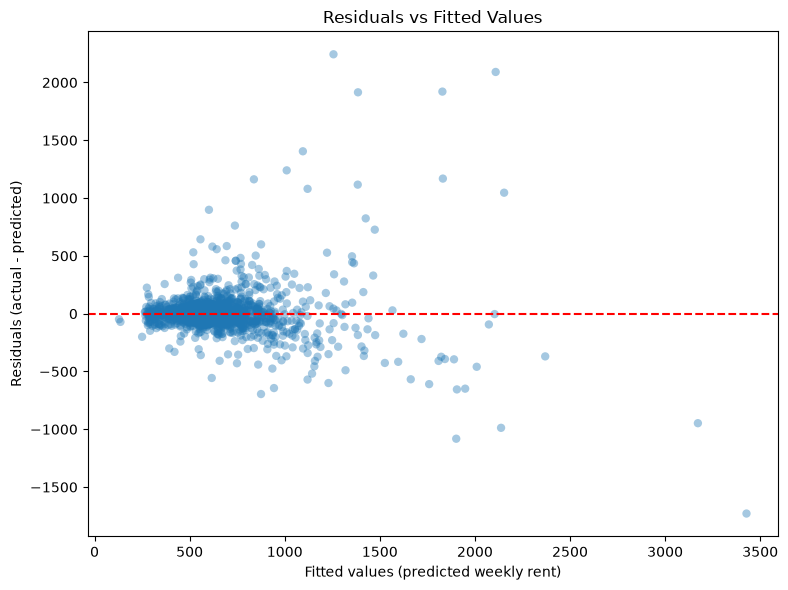

In [71]:
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance

# Residuals vs fitted values
residuals = y_test - y_pred

plt.figure(figsize=(8, 6))
plt.scatter(y_pred, residuals, alpha=0.4, edgecolor="none")
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Fitted values (predicted weekly rent)")
plt.ylabel("Residuals (actual - predicted)")
plt.title("Residuals vs Fitted Values")
plt.tight_layout()
plt.show()

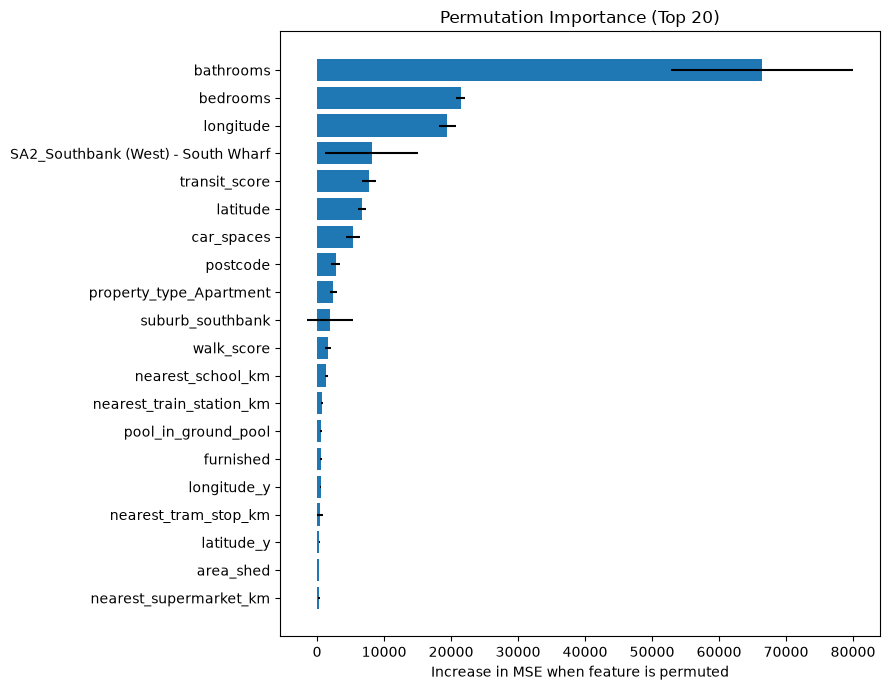

In [72]:
# Permutation importance (on the test set)
perm = permutation_importance(
    model,
    X_test,
    y_test,
    n_repeats=5,
    random_state=42,
    n_jobs=-1,
    scoring="neg_mean_squared_error",
)

top_n = 20
sorted_idx = perm.importances_mean.argsort()[::-1][:top_n]

plt.figure(figsize=(9, 7))
plt.barh(
    X_test.columns[sorted_idx][::-1],
    perm.importances_mean[sorted_idx][::-1],
    xerr=perm.importances_std[sorted_idx][::-1],
)
plt.xlabel("Increase in MSE when feature is permuted")
plt.title(f"Permutation Importance (Top {top_n})")
plt.tight_layout()
plt.show()

In [74]:
print(X.columns)

Index(['id', 'latitude', 'longitude', 'postcode', 'bedrooms', 'bathrooms',
       'ensuites', 'car_spaces', 'furnished', 'partially_furnished',
       ...
       'property_type_Flat', 'property_type_House', 'property_type_Other',
       'property_type_Serviced Apartment', 'property_type_Studio',
       'property_type_Terrace', 'property_type_Townhouse',
       'property_type_Unit', 'property_type_Villa', 'property_type_Warehouse'],
      dtype='str', length=1283)


In [76]:
X.head(0).to_csv("column_headers.csv", index=False)